# Predicting Airline Satisfaction
### 03 · Entrenamiento, evaluación y optimización de modelos

**Competencia:** [Kaggle · Playground Series S6E10](https://www.kaggle.com/competitions/playground-series-s6e10/overview)  
**Problema:** clasificación binaria de la satisfacción de pasajeros (`True` = satisfecho; `False` = insatisfecho).  
**Métrica principal:** ROC-AUC. Cuanto mayor sea, mejor distingue el modelo entre ambas clases.

En este notebook comparamos **Regresión Logística** y **Random Forest**. Primero los entrenamos con los datos preparados en `02_preprocessing.ipynb` y, después, utilizamos **Pipelines**, **validación cruzada** y **búsqueda de hiperparámetros** para elegir el modelo final.

> **Alcance:** aquí seleccionamos el modelo. En `04_submission.ipynb` lo entrenamos nuevamente con el 100 % de los datos etiquetados y preparamos las predicciones para Kaggle. No usamos el archivo `test.csv` para entrenar ni para seleccionar hiperparámetros.

## Guía de lectura

1. **Datos preparados:** recuperar la partición 80/20 del notebook anterior.
2. **Regresión Logística inicial:** entrenamiento, curva ROC, métricas y matriz de confusión.
3. **Random Forest inicial:** entrenamiento, métricas e importancia de las variables.
4. **Pipelines:** automatizar la imputación y codificación desde los datos originales.
5. **Validación cruzada:** comparar el rendimiento promedio de ambos algoritmos.
6. **Optimización:** probar hiperparámetros con `RandomizedSearchCV` y `GridSearchCV`.
7. **Comparación final:** seleccionar el modelo que utilizaremos en la entrega.

Trabajamos con una partición estratificada (**80 % entrenamiento y 20 % validación**), usando `random_state=42` para reproducir los resultados.

## 1. Carga de datos preparados

El notebook `02_preprocessing.ipynb` guardó los conjuntos de entrenamiento y validación, junto con los transformadores utilizados. Aquí los recuperamos para analizar primero los modelos de forma manual.

Localizamos la carpeta principal del proyecto sin utilizar rutas personales de Windows. **Antes de ejecutar esta sección, ejecuta el notebook 02** para generar `data/processed/datos_preprocesados.pkl`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Ubicación del proyecto, desde notebooks/ o desde su carpeta raíz.
carpeta_actual = Path.cwd()
if (carpeta_actual / "data" / "train.csv").is_file():
    proyecto = carpeta_actual
elif (carpeta_actual.parent / "data" / "train.csv").is_file():
    proyecto = carpeta_actual.parent
else:
    raise FileNotFoundError(
        "No se encontró data/train.csv. Abre el proyecto desde su raíz o desde notebooks/."
    )

ruta_procesados = proyecto / "data" / "processed" / "datos_preprocesados.pkl"
if not ruta_procesados.exists():
    raise FileNotFoundError(
        "Falta data/processed/datos_preprocesados.pkl. Ejecuta primero 02_preprocessing.ipynb."
    )

datos = pd.read_pickle(ruta_procesados)
X_train_final = datos["X_train_final"]
X_val_final = datos["X_val_final"]
y_train = datos["y_train"]
y_val = datos["y_val"]

print("Entrenamiento:", X_train_final.shape)
print("Validación:", X_val_final.shape)
print("Características preprocesadas:", X_train_final.shape[1])
assert X_train_final.columns.equals(X_val_final.columns)
assert X_train_final.index.equals(y_train.index)
assert X_val_final.index.equals(y_val.index)

Entrenamiento: (559708, 26)
Validación: (139927, 26)
Características preprocesadas: 26


## 2. Regresión Logística: modelo inicial

Empezamos con Regresión Logística porque es una referencia sencilla de interpretar. Antes de entrenarla, estandarizamos las variables: este procedimiento ayuda a que las diferencias de escala no dificulten el ajuste del modelo.

**Importante:** ajustamos el `StandardScaler` solamente con entrenamiento y aplicamos esa misma transformación a validación. Así evitamos incorporar información de validación durante el ajuste.

In [2]:
escalador = StandardScaler()
X_train_escalado = escalador.fit_transform(X_train_final)
X_val_escalado = escalador.transform(X_val_final)

modelo_logistico = LogisticRegression(max_iter=1000)
modelo_logistico.fit(X_train_escalado, y_train)

predicciones_val = modelo_logistico.predict(X_val_escalado)
probabilidades_val = modelo_logistico.predict_proba(X_val_escalado)

# Verificamos cuál es la clase positiva antes de seleccionar su probabilidad.
print("Orden de las clases:", modelo_logistico.classes_)
assert list(modelo_logistico.classes_) == [False, True]
prob_satisfaccion = probabilidades_val[:, 1]

auc_logistico = roc_auc_score(y_val, prob_satisfaccion)
accuracy_logistico = accuracy_score(y_val, predicciones_val)
precision_logistico = precision_score(y_val, predicciones_val)
recall_logistico = recall_score(y_val, predicciones_val)
f1_logistico = f1_score(y_val, predicciones_val)

print(f"ROC-AUC:   {auc_logistico:.6f}")
print(f"Accuracy:  {accuracy_logistico:.6f}")
print(f"Precision: {precision_logistico:.6f}")
print(f"Recall:    {recall_logistico:.6f}")
print(f"F1-Score:  {f1_logistico:.6f}")

Orden de las clases: [False  True]
ROC-AUC:   0.920459
Accuracy:  0.878058
Precision: 0.874823
Recall:    0.846169
F1-Score:  0.860257


### Curva ROC

La curva ROC muestra cómo cambia la proporción de verdaderos positivos frente a la de falsos positivos cuando modificamos el umbral de clasificación. La línea diagonal representa el comportamiento de un clasificador aleatorio.

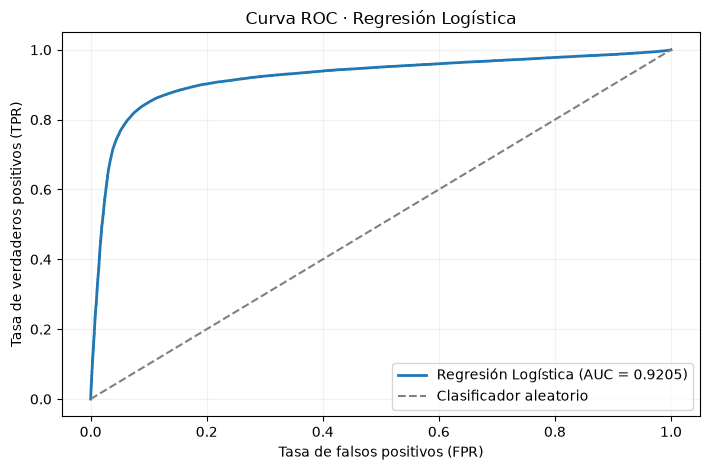

In [3]:
fpr, tpr, umbrales = roc_curve(y_val, prob_satisfaccion)

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.plot(fpr, tpr, label=f"Regresión Logística (AUC = {auc_logistico:.4f})", linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador aleatorio")
ax.set(title="Curva ROC · Regresión Logística",
       xlabel="Tasa de falsos positivos (FPR)",
       ylabel="Tasa de verdaderos positivos (TPR)")
ax.legend()
ax.grid(alpha=0.18)
fig.tight_layout()
plt.show()

### Matriz de confusión

Para convertir las probabilidades en `True` o `False`, `predict()` usa el umbral predeterminado del modelo. La matriz de confusión muestra los aciertos y errores de esa clasificación. **ROC-AUC**, en cambio, evalúa las probabilidades a través de distintos umbrales.

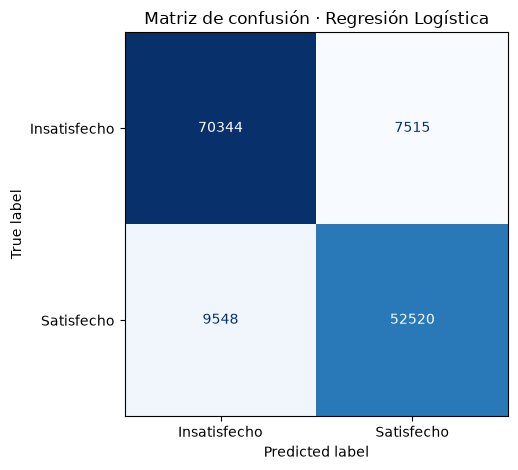

Matriz de confusión:
 [[70344  7515]
 [ 9548 52520]]


In [4]:
matriz_confusion = confusion_matrix(y_val, predicciones_val, labels=[False, True])

fig, ax = plt.subplots(figsize=(6.4, 4.8))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=["Insatisfecho", "Satisfecho"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Matriz de confusión · Regresión Logística")
fig.tight_layout()
plt.show()

print("Matriz de confusión:\n", matriz_confusion)

### Comparar entrenamiento y validación

Calculamos el ROC-AUC también sobre entrenamiento. Si la diferencia con validación fuera demasiado grande, podría ser una señal de sobreajuste; una brecha pequeña, por sí sola, no garantiza que el modelo sea perfecto.

In [5]:
probabilidades_train = modelo_logistico.predict_proba(X_train_escalado)[:, 1]
auc_train = roc_auc_score(y_train, probabilidades_train)
brecha_auc = auc_train - auc_logistico

print(f"ROC-AUC entrenamiento: {auc_train:.6f}")
print(f"ROC-AUC validación:    {auc_logistico:.6f}")
print(f"Brecha:                {brecha_auc:.6f}")

ROC-AUC entrenamiento: 0.921877
ROC-AUC validación:    0.920459
Brecha:                0.001418


**Lectura inicial.** La regresión logística logra una buena capacidad de discriminación y una brecha pequeña entre entrenamiento y validación. La usaremos como punto de referencia antes de probar un algoritmo capaz de capturar relaciones no lineales.

## 3. Random Forest: modelo inicial

Probamos un bosque aleatorio con **50 árboles** y **profundidad máxima 12**. Al estar basado en árboles, no necesita `StandardScaler`; utilizamos directamente las 26 columnas numéricas que preparamos en el notebook 02.

Lo evaluamos sobre exactamente los mismos pasajeros de validación que la regresión logística.

In [6]:
modelo_rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=12,
    random_state=42,
    n_jobs=-1,
)
modelo_rf.fit(X_train_final, y_train)

predicciones_rf = modelo_rf.predict(X_val_final)
prob_satisfaccion_rf = modelo_rf.predict_proba(X_val_final)[:, 1]

auc_rf = roc_auc_score(y_val, prob_satisfaccion_rf)
accuracy_rf = accuracy_score(y_val, predicciones_rf)
precision_rf = precision_score(y_val, predicciones_rf)
recall_rf = recall_score(y_val, predicciones_rf)
f1_rf = f1_score(y_val, predicciones_rf)

auc_rf_train = roc_auc_score(
    y_train,
    modelo_rf.predict_proba(X_train_final)[:, 1]
)

print(f"ROC-AUC validación:    {auc_rf:.6f}")
print(f"ROC-AUC entrenamiento: {auc_rf_train:.6f}")
print(f"Accuracy:              {accuracy_rf:.6f}")
print(f"Precision:             {precision_rf:.6f}")
print(f"Recall:                {recall_rf:.6f}")
print(f"F1-Score:              {f1_rf:.6f}")

ROC-AUC validación:    0.954595
ROC-AUC entrenamiento: 0.960422
Accuracy:              0.919858
Precision:             0.915623
Recall:                0.902494
F1-Score:              0.909011


### Matriz de confusión de Random Forest

Esta gráfica nos ayuda a comparar cuántos pasajeros clasificó correctamente cada modelo y qué tipo de errores comete.

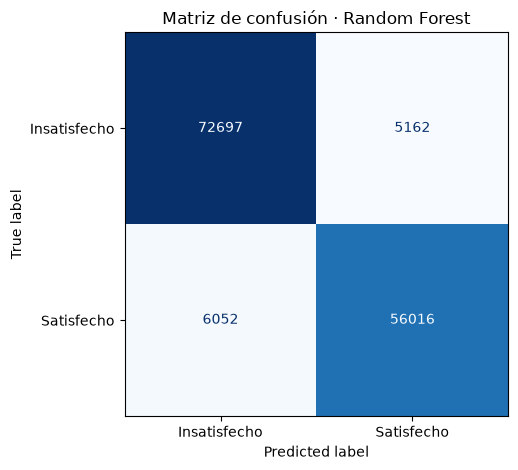

Matriz de confusión:
 [[72697  5162]
 [ 6052 56016]]


In [7]:
matriz_rf = confusion_matrix(y_val, predicciones_rf, labels=[False, True])

fig, ax = plt.subplots(figsize=(6.4, 4.8))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=["Insatisfecho", "Satisfecho"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Matriz de confusión · Random Forest")
fig.tight_layout()
plt.show()

print("Matriz de confusión:\n", matriz_rf)

### Importancia de las variables

Random Forest permite observar qué variables contribuyeron más a las divisiones de los árboles. Aquí utilizamos `feature_importances_`, una medida basada en la reducción de impureza.

**Precaución:** estas importancias son predictivas, no causales; además, pueden favorecer algunas características y repartir la importancia entre variables relacionadas.

,Variable,Importancia
7,Online boarding,0.203582
23,Class_Business,0.122252
2,Inflight wifi service,0.106014
22,Type of Travel_Personal Travel,0.076065
9,Inflight entertainment,0.065667
21,Type of Travel_Business travel,0.060816
24,Class_Eco,0.056528
8,Seat comfort,0.051484
19,Customer Type_Loyal Customer,0.030957
11,Leg room service,0.030882


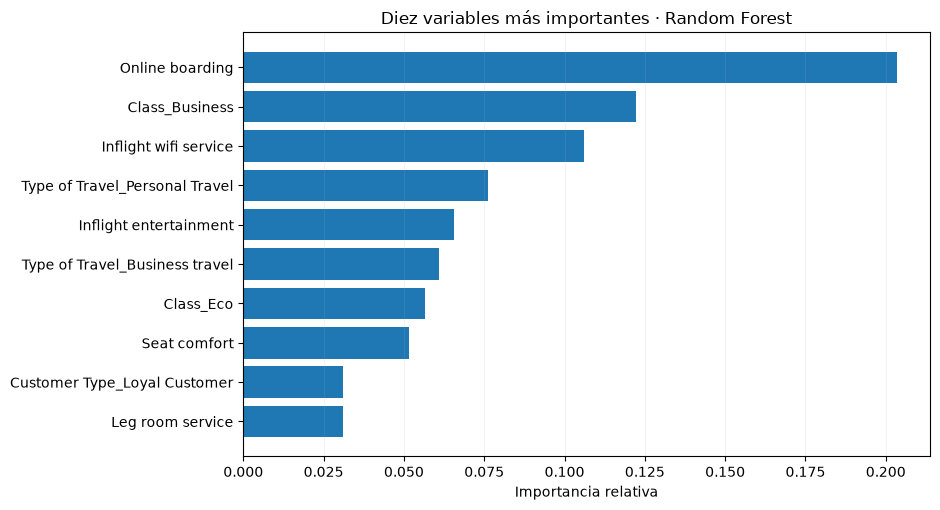

In [8]:
df_importancias = pd.DataFrame({
    "Variable": X_train_final.columns,
    "Importancia": modelo_rf.feature_importances_,
}).sort_values("Importancia", ascending=False)

assert abs(df_importancias["Importancia"].sum() - 1.0) < 1e-6

top_10 = df_importancias.head(10)
display(top_10)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.barh(top_10["Variable"], top_10["Importancia"])
ax.invert_yaxis()
ax.set(xlabel="Importancia relativa", title="Diez variables más importantes · Random Forest")
ax.grid(axis="x", alpha=0.15)
fig.tight_layout()
plt.show()

### Primera comparación

La tabla resume cuatro métricas de clasificación y ROC-AUC para ambos modelos iniciales. Se calculan en el **mismo conjunto de validación**, por lo que podemos comparar directamente sus resultados.

In [9]:
resumen_inicial = pd.DataFrame([
    {
        "Modelo": "Regresión Logística",
        "ROC-AUC": auc_logistico,
        "Accuracy": accuracy_logistico,
        "Precision": precision_logistico,
        "Recall": recall_logistico,
        "F1": f1_logistico,
    },
    {
        "Modelo": "Random Forest",
        "ROC-AUC": auc_rf,
        "Accuracy": accuracy_rf,
        "Precision": precision_rf,
        "Recall": recall_rf,
        "F1": f1_rf,
    },
]).set_index("Modelo")

display(resumen_inicial.round(4))

,ROC-AUC,Accuracy,Precision,Recall,F1
Modelo,,,,,
Regresión Logística,0.9205,0.8781,0.8748,0.8462,0.8603
Random Forest,0.9546,0.9199,0.9156,0.9025,0.9090


**Interpretación.** Random Forest presenta una mejora clara respecto a Regresión Logística en este conjunto de datos. Antes de elegirlo definitivamente, vamos a automatizar el preprocesamiento y evaluar la estabilidad del resultado mediante validación cruzada.

## 4. Preprocesamiento y modelos con Pipeline

Hasta ahora utilizamos las columnas transformadas manualmente en el notebook 02. Para la búsqueda de hiperparámetros es más conveniente crear **Pipelines**, de manera que cada fold aprenda su propia imputación y codificación **solo de las filas que utiliza para entrenar**.

Recargamos `train.csv` y repetimos la **misma división 80/20** (`random_state=42`, `stratify=y`). Así podemos comparar de forma coherente con los resultados anteriores.

In [10]:
datos_originales = pd.read_csv(proyecto / "data" / "train.csv")
X_pipeline = datos_originales.drop(columns=["id", "satisfaction"])
y_pipeline = datos_originales["satisfaction"]

X_train_pipeline, X_val_pipeline, y_train_pipeline, y_val_pipeline = train_test_split(
    X_pipeline,
    y_pipeline,
    test_size=0.2,
    random_state=42,
    stratify=y_pipeline,
)

# Confirmar que conservamos la misma partición utilizada en el notebook 02.
assert X_train_pipeline.index.equals(X_train_final.index)
assert X_val_pipeline.index.equals(X_val_final.index)
assert y_train_pipeline.equals(y_train)
assert y_val_pipeline.equals(y_val)

columnas_numericas = X_train_pipeline.select_dtypes(include="number").columns
columnas_categoricas_pipeline = X_train_pipeline.select_dtypes(include="object").columns

print("Filas entrenamiento:", len(X_train_pipeline))
print("Filas validación:", len(X_val_pipeline))
print("Columnas numéricas:", len(columnas_numericas))
print("Columnas categóricas:", len(columnas_categoricas_pipeline))

Filas entrenamiento: 559708
Filas validación: 139927
Columnas numéricas: 17
Columnas categóricas: 4


C:\Users\jrestrepo\AppData\Local\Temp\ipykernel_24544\2411308166.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas_pipeline = X_train_pipeline.select_dtypes(include="object").columns


### Pipeline de Regresión Logística

En las variables numéricas imputamos la mediana y aplicamos `StandardScaler`; en las categóricas imputamos la moda y usamos `OneHotEncoder`. Ambas operaciones se ejecutan dentro del `ColumnTransformer`.

El modelo logístico manual estandarizaba **todas las columnas ya codificadas**, mientras que este Pipeline escala solamente las numéricas. Por eso sus ROC-AUC pueden diferir levemente.

In [11]:
pipeline_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
])

pipeline_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocesador = ColumnTransformer(transformers=[
    ("numericas", pipeline_numerico, columnas_numericas),
    ("categoricas", pipeline_categorico, columnas_categoricas_pipeline),
])

pipeline_logistico = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000)),
])

pipeline_logistico.fit(X_train_pipeline, y_train_pipeline)
prob_satisfaccion_pipeline = pipeline_logistico.predict_proba(X_val_pipeline)[:, 1]
auc_pipeline = roc_auc_score(y_val_pipeline, prob_satisfaccion_pipeline)

print(f"ROC-AUC logístico manual:   {auc_logistico:.6f}")
print(f"ROC-AUC logístico Pipeline: {auc_pipeline:.6f}")

ROC-AUC logístico manual:   0.920459
ROC-AUC logístico Pipeline: 0.920455


### Pipeline de Random Forest

Utilizamos la mediana para las numéricas, pero **no las escalamos**. El tratamiento de categorías es el mismo que en el Pipeline anterior. Ambos modelos incorporan ahora sus transformaciones dentro del proceso de entrenamiento.

In [12]:
preprocesador_rf = ColumnTransformer(transformers=[
    ("numericas", SimpleImputer(strategy="median"), columnas_numericas),
    ("categoricas", pipeline_categorico, columnas_categoricas_pipeline),
])

pipeline_rf = Pipeline(steps=[
    ("preprocesamiento", preprocesador_rf),
    ("modelo", RandomForestClassifier(
        n_estimators=50,
        max_depth=12,
        random_state=42,
        n_jobs=-1,
    )),
])

pipeline_rf.fit(X_train_pipeline, y_train_pipeline)
prob_satisfaccion_pipeline_rf = pipeline_rf.predict_proba(X_val_pipeline)[:, 1]
auc_pipeline_rf = roc_auc_score(y_val_pipeline, prob_satisfaccion_pipeline_rf)

print(f"ROC-AUC RF manual:   {auc_rf:.6f}")
print(f"ROC-AUC RF Pipeline: {auc_pipeline_rf:.6f}")

ROC-AUC RF manual:   0.954595
ROC-AUC RF Pipeline: 0.954595


## 5. Validación cruzada estratificada

La evaluación en un único conjunto de validación puede depender de la partición concreta de los datos. Para comprobar la estabilidad utilizamos **3 folds estratificados**, siempre dentro del **80 % de entrenamiento**.

Como el preprocesamiento forma parte de los Pipelines, cada fold ajusta medianas y categorías únicamente con sus datos de entrenamiento. La métrica utilizada sigue siendo ROC-AUC.

In [13]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

resultados_cv_logistico = cross_val_score(
    pipeline_logistico, X_train_pipeline, y_train_pipeline,
    cv=cv, scoring="roc_auc", n_jobs=1,
)

resultados_cv_rf = cross_val_score(
    pipeline_rf, X_train_pipeline, y_train_pipeline,
    cv=cv, scoring="roc_auc", n_jobs=1,
)

auc_cv_promedio = resultados_cv_logistico.mean()
auc_cv_desviacion = resultados_cv_logistico.std()
auc_cv_rf_promedio = resultados_cv_rf.mean()
auc_cv_rf_desviacion = resultados_cv_rf.std()

resumen_cv = pd.DataFrame({
    "Modelo": ["Regresión Logística", "Random Forest"],
    "ROC-AUC CV promedio": [auc_cv_promedio, auc_cv_rf_promedio],
    "Desviación estándar": [auc_cv_desviacion, auc_cv_rf_desviacion],
    "Fold 1": [resultados_cv_logistico[0], resultados_cv_rf[0]],
    "Fold 2": [resultados_cv_logistico[1], resultados_cv_rf[1]],
    "Fold 3": [resultados_cv_logistico[2], resultados_cv_rf[2]],
})
display(resumen_cv.round(6))

,Modelo,ROC-AUC CV promedio,Desviación estándar,Fold 1,Fold 2,Fold 3
0,Regresión Logística,0.921857,0.000252,0.921501,0.922024,0.922047
1,Random Forest,0.955796,0.000186,0.956058,0.955644,0.955686


**Interpretación.** La desviación estándar describe cuánto variaron los ROC-AUC entre los tres folds. En nuestros experimentos fueron valores pequeños y Random Forest mantuvo la ventaja. Esto es una señal favorable de estabilidad, aunque la validación cruzada tampoco garantiza el mismo resultado en datos futuros.

## 6. Optimización de Random Forest

Utilizamos `RandomizedSearchCV` para probar **5 combinaciones** de un espacio de **36 posibles**. Cada combinación se evalúa en tres folds: son **15 ajustes de validación cruzada** y, al finalizar, un ajuste adicional sobre todo el conjunto de entrenamiento con la configuración ganadora.

El criterio de selección es el **ROC-AUC promedio de validación cruzada**, no el ROC-AUC de validación externa.

In [14]:
parametros_rf = {
    "modelo__n_estimators": [50, 100],
    "modelo__max_depth": [10, 12, 16],
    "modelo__min_samples_split": [2, 5],
    "modelo__min_samples_leaf": [1, 2, 4],
}

busqueda_rf = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=parametros_rf,
    n_iter=5,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
)
busqueda_rf.fit(X_train_pipeline, y_train_pipeline)

mejores_parametros = busqueda_rf.best_params_
mejor_auc = busqueda_rf.best_score_
modelo_rf_optimizado = busqueda_rf.best_estimator_

print("Mejores hiperparámetros:", mejores_parametros)
print(f"ROC-AUC CV original:   {auc_cv_rf_promedio:.6f}")
print(f"ROC-AUC CV optimizado: {mejor_auc:.6f}")

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Mejores hiperparámetros: {'modelo__n_estimators': 100, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 4, 'modelo__max_depth': 16}
ROC-AUC CV original:   0.955796
ROC-AUC CV optimizado: 0.956819


### Comparar todas las configuraciones evaluadas

No basta con ver solamente la mejor opción: también es útil comparar el desempeño, la variabilidad y el tiempo promedio de ajuste de las otras cuatro combinaciones.

In [15]:
df_busqueda_rf = pd.DataFrame(busqueda_rf.cv_results_)
columnas_resultados = [
    "param_modelo__n_estimators",
    "param_modelo__max_depth",
    "param_modelo__min_samples_split",
    "param_modelo__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "rank_test_score",
]

df_resultados_rf = (
    df_busqueda_rf[columnas_resultados]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)
display(df_resultados_rf.round(6))

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_split,param_modelo__min_samples_leaf,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,100,16,5,4,0.956819,0.000239,18.194452,1
1,50,16,5,2,0.956643,0.000241,9.163586,2
2,50,16,5,1,0.956605,0.000237,9.630726,3
3,100,12,2,1,0.955827,0.000245,15.437075,4
4,50,12,2,2,0.955734,0.000209,8.648003,5


### Evaluación del Random Forest optimizado

`best_estimator_` ya incluye el Pipeline ganador entrenado con todo el **80 % de entrenamiento**. Lo evaluamos en validación solo para comprobar si el rendimiento observado en CV también se refleja en esos pasajeros.

In [16]:
prob_satisfaccion_optimizada = modelo_rf_optimizado.predict_proba(
    X_val_pipeline
)[:, 1]
auc_rf_optimizado = roc_auc_score(
    y_val_pipeline, prob_satisfaccion_optimizada
)

print(f"ROC-AUC RF original en validación:   {auc_rf:.6f}")
print(f"ROC-AUC RF optimizado en validación: {auc_rf_optimizado:.6f}")
print(f"Diferencia: {auc_rf_optimizado - auc_rf:+.6f}")

ROC-AUC RF original en validación:   0.954595
ROC-AUC RF optimizado en validación: 0.955916
Diferencia: +0.001321


**Interpretación.** La configuración ganadora utiliza 100 árboles, profundidad máxima 16, mínimo de 5 observaciones para dividir un nodo y mínimo de 4 por hoja. En nuestros resultados la mejora fue pequeña, pero positiva. No podemos identificar un único hiperparámetro como responsable, porque cambiaron varios simultáneamente.

## 7. Optimización de Regresión Logística

Para comparar también una versión optimizada del modelo de referencia, probamos seis valores del parámetro `C` mediante **`GridSearchCV`**. A diferencia de la búsqueda aleatoria, aquí se evalúan **todos** los valores propuestos.

`C` controla la regularización de forma inversa: valores menores implican una regularización más intensa. Mantenemos el mismo Pipeline y los mismos tres folds.

In [17]:
parametros_logistico = {
    "modelo__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

busqueda_logistica = GridSearchCV(
    estimator=pipeline_logistico,
    param_grid=parametros_logistico,
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    verbose=1,
)
busqueda_logistica.fit(X_train_pipeline, y_train_pipeline)

mejores_parametros_logisticos = busqueda_logistica.best_params_
mejor_auc_logistico = busqueda_logistica.best_score_
modelo_logistico_optimizado = busqueda_logistica.best_estimator_

print("Mejor C:", mejores_parametros_logisticos)
print(f"ROC-AUC CV original:   {auc_cv_promedio:.6f}")
print(f"ROC-AUC CV optimizado: {mejor_auc_logistico:.6f}")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Mejor C: {'modelo__C': 0.01}
ROC-AUC CV original:   0.921857
ROC-AUC CV optimizado: 0.921859


In [18]:
df_resultados_logistica = (
    pd.DataFrame(busqueda_logistica.cv_results_)[[
        "param_modelo__C", "mean_test_score", "std_test_score", "rank_test_score"
    ]]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)
display(df_resultados_logistica.round(7))

auc_logistico_optimizado = roc_auc_score(
    y_val_pipeline,
    modelo_logistico_optimizado.predict_proba(X_val_pipeline)[:, 1]
)

print(f"ROC-AUC logístico original (Pipeline): {auc_pipeline:.6f}")
print(f"ROC-AUC logístico optimizado:          {auc_logistico_optimizado:.6f}")

,param_modelo__C,mean_test_score,std_test_score,rank_test_score
0,0.010,0.921859,0.000253,1
1,0.100,0.921859,0.000253,2
2,1.000,0.921857,0.000252,3
3,10.000,0.921857,0.000252,4
4,100.000,0.921857,0.000252,5
5,0.001,0.921743,0.000256,6


ROC-AUC logístico original (Pipeline): 0.920455
ROC-AUC logístico optimizado:          0.920457


**Interpretación.** La búsqueda seleccionó `C = 0.01`, pero la diferencia de ROC-AUC respecto al modelo logístico inicial fue prácticamente nula. Esto nos recuerda que **optimizar no garantiza una mejora relevante** y que el valor ganador depende del conjunto de datos y del espacio de búsqueda definido.

## 8. Comparación final y selección del modelo

La siguiente tabla utiliza el **mismo conjunto de validación** para las cuatro configuraciones y el **mismo procedimiento de tres folds** para los ROC-AUC de validación cruzada. Para la regresión logística inicial, el valor CV corresponde a su versión con Pipeline, que aplica la misma familia de modelo con una pequeña diferencia de escalado respecto a la versión manual.

La comparación sirve para escoger una configuración. Como consultamos los resultados de validación durante el desarrollo, **esa validación no debe presentarse como una prueba final completamente independiente de la selección del modelo**.

In [19]:
comparacion_final = pd.DataFrame([
    {
        "Modelo": "Regresión Logística · inicial",
        "ROC-AUC CV": auc_cv_promedio,
        "ROC-AUC validación": auc_pipeline,
    },
    {
        "Modelo": "Regresión Logística · optimizada",
        "ROC-AUC CV": mejor_auc_logistico,
        "ROC-AUC validación": auc_logistico_optimizado,
    },
    {
        "Modelo": "Random Forest · inicial",
        "ROC-AUC CV": auc_cv_rf_promedio,
        "ROC-AUC validación": auc_pipeline_rf,
    },
    {
        "Modelo": "Random Forest · optimizado",
        "ROC-AUC CV": mejor_auc,
        "ROC-AUC validación": auc_rf_optimizado,
    },
]).sort_values("ROC-AUC CV", ascending=False)

display(comparacion_final.set_index("Modelo").round(6))
print("Mayor ROC-AUC CV:", comparacion_final.iloc[0]["Modelo"])
print("Hiperparámetros de Random Forest optimizado:", mejores_parametros)

,ROC-AUC CV,ROC-AUC validación
Modelo,,
Random Forest · optimizado,0.956819,0.955916
Random Forest · inicial,0.955796,0.954595
Regresión Logística · optimizada,0.921859,0.920457
Regresión Logística · inicial,0.921857,0.920455


Mayor ROC-AUC CV: Random Forest · optimizado
Hiperparámetros de Random Forest optimizado: {'modelo__n_estimators': 100, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 4, 'modelo__max_depth': 16}


## 9. Conclusiones y siguiente etapa

- **Random Forest obtuvo mejores resultados que Regresión Logística** para predecir la satisfacción de los pasajeros en este conjunto de datos.
- **La validación cruzada mostró poca variación entre folds** para ambos algoritmos, lo que aporta confianza en la estabilidad de la comparación.
- **RandomizedSearchCV mejoró ligeramente Random Forest.** La mejor configuración encontrada fue: `n_estimators=100`, `max_depth=16`, `min_samples_split=5` y `min_samples_leaf=4`.
- **GridSearchCV seleccionó `C=0.01` para la Regresión Logística**, pero la mejora fue tan pequeña que no representa una diferencia práctica importante.

### Resultados obtenidos en este ejercicio

| Modelo | ROC-AUC CV | ROC-AUC en validación |
|---|---:|---:|
| Regresión Logística inicial (Pipeline) | 0.921857 | 0.920455 |
| Regresión Logística optimizada | 0.921859 | 0.920457 |
| Random Forest inicial | 0.955796 | 0.954595 |
| **Random Forest optimizado** | **0.956819** | **0.955916** |

> Los valores de esta tabla corresponden a los resultados observados con `random_state=42` y el mismo conjunto de datos utilizado en el proyecto. La tabla calculada en la sección anterior es la referencia dinámica al volver a ejecutar el notebook.

**Decisión:** seleccionamos **Random Forest optimizado** para preparar nuestra primera entrega a Kaggle. En [`04_submission.ipynb`](04_submission.ipynb) reconstruimos el Pipeline final, lo ajustamos con todos los registros etiquetados de `train.csv` y generamos las probabilidades para `test.csv`.

**Lo que aprendimos:** comparar modelos, utilizar distintas métricas, evaluar la capacidad de generalización, automatizar el preprocesamiento y ajustar hiperparámetros sin usar los datos de Kaggle como entrenamiento. No realizamos *Feature Engineering* ni entrenamos XGBoost en esta versión del proyecto.